# MVP twin test: the preregistered comparison on the evaluation window

Notebook 05 ran the twin on the training window's web interviews, and the preregistration `docs/prereg/mvp-twin.md`
(registered on OSF as https://osf.io/ahgkw) then fixed how it would be tested. This notebook reports that test: Llama
3.1 8B predicts the answers of the 21,183 interviews of August 2024 to February 2026, and its predictions are compared
with those of the supervised models of notebook 04.

The test is inconclusive. The twin's advantage over the logit and the baseline shares does not rise with how unlike the
training data a month's inputs are. It rises with elapsed time instead, which the plan did not test and section 5
traces mostly to the logit's growing errors in 2025.

It covers, in order: the plan, the run, how the test works, the outcome, why the months came out as they did, the
plan's other analyses, deviations from the plan, and what the study establishes.

Results are read from `experiments/mvp/2026-11-05-twin-prereg-scores/`, written by
`python -m sdt.mvp.twin_score twin-prereg-scores`, and from the two runs it scores: the twins in
`2026-11-05-twin-prereg-eval/` and the supervised models in `2026-10-26-supervised-macro-politics-ridge/`. Their
per-interview files are not in git.

In [1]:
import json, warnings
warnings.filterwarnings('ignore', message='IProgress not found')        # quiet a library warning
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from sdt.mvp import twin
from sdt.mvp.clean import CLASSES, OUT_PATH, OUTCOMES
from sdt.mvp.encode import state_table
from sdt.mvp.primary import COMPARATORS, TWIN
from sdt.mvp.run import EXPERIMENTS
from sdt.mvp.windows import split
pd.set_option('display.max_columns', None); pd.set_option('display.width', None)
ITEMS = list(OUTCOMES)
DMP, LOGIT = 'demographics_macro_politics', 'mnl_demographics_macro_politics'
NAMES = {TWIN: 'shifted twin', LOGIT: 'logit', 'baseline': 'baseline shares'}
SHORT = {'demographics': 'D', 'demographics_macro': 'D+M', 'demographics_politics': 'D+P', DMP: 'D+M+P'}
month = lambda m: pd.to_datetime(pd.Series(m).astype(str), format='%Y%m')
period = lambda m: 'Baseline' if m < 202411 else 'Flip' if m < 202502 else 'Tariffs'

clean = pd.read_parquet(OUT_PATH)
train, test = split(clean)
key = clean.set_index('CASEID')
SCORES = EXPERIMENTS / '2026-11-05-twin-prereg-scores'
TWINS = EXPERIMENTS / '2026-11-05-twin-prereg-eval'
SUPERVISED = EXPERIMENTS / '2026-10-26-supervised-macro-politics-ridge'
scores = pd.read_csv(SCORES / 'scores.csv')
primary = json.load(open(SCORES / 'primary.json'))
months = pd.read_csv(SCORES / 'primary_months.csv').set_index('month')
distances = pd.read_csv(SCORES / 'primary_distances.csv')
rho_draws = pd.read_csv(SCORES / 'rho_draws.csv')
by_period = pd.read_csv(SCORES / 'calibration_by_period.csv')
meta, twin_meta = json.load(open(SCORES / 'run.json')), json.load(open(TWINS / 'run.json'))
print(f"Scoring run of {meta['date']} at commit {meta['commit'][:7]}; twin run at commit {twin_meta['commit'][:7]}; "
      f"supervised run at commit {meta['sources']['supervised']['commit'][:7]}")

Scoring run of 2026-11-05 at commit 0f6b6bc; twin run at commit e4b385b; supervised run at commit 53877d8


## 1. The plan

The plan states the hypothesis as: an LLM twin's accuracy in predicting survey answers, relative to supervised models
given the same inputs, increases as the inputs become less like those of the training data. The inputs are the 11
respondent attributes of notebook 03 and the 10 state variables of notebook 04, which the twin reads as text and the
supervised models as features.

The hypothesis concerns the trend of the twin's relative accuracy, not its level. Notebook 05, section 3 explains why:
the twin has never seen an answer recorded on this survey's form, so it is almost certainly worse than the supervised
models at how the form turns opinions into answers. If the form works the same way in every month, that handicap is
the same in every month, so only a change in relative accuracy across months bears on the hypothesis.

The test is blind on the twin's side only. When the plan was registered on 3 November 2026, every evaluation answer and
every supervised model's evaluation score were known, as were the twin's predictions for the training window's web
interviews, but no twin prediction for an evaluation interview existed.

The primary test compares the shifted twin on D+M+P with two comparators: the logit on D+M+P and the baseline shares.
The shifted twin adds a fitted constant to the log-odds of each answer, so that its answer shares match those of the
2,257 training web interviews (notebook 05, section 3.1). The logit and the baseline shares match those shares too, so
each of the three models misses a later month's shares only by its error in how they moved since then.

The plan also lists secondary analyses, which do not bear on the outcome: periods, other twins and supervised models,
the individual score, items, parties, and two diagnostics. Any other analysis is labelled exploratory.

## 2. The run

The twin run used the pilot's command (notebook 05, section 4) at the commit that the preregistration tag points to,
with the evaluation interviews added: Llama 3.1 8B Instruct in fp32 at batch size 16, on NVIDIA RTX PRO 6000 GPUs.
Four GPUs each ran one feature set in parallel, and a separate machine, set up identically, assembled their outputs,
so the run's recorded time per stage is GPU time (about 3.5 hours of wall-clock time) and its `run.json` does not
record the number of GPUs. Its probabilities for the training web interviews reproduce the pilot's exactly:

In [2]:
pilot = pd.read_parquet(EXPERIMENTS / '2026-10-30-twin-pilot-training-web' / 'option_probs.parquet')
raw = pd.read_parquet(TWINS / 'option_probs.parquet')
both = pilot[pilot.stage == 'base'].merge(raw[raw.interviews == 'train-web'], on=['feature_set', 'item', 'CASEID'],
                                          suffixes=('_pilot', '_eval'))
same = all(np.array_equal(both[f'{c}_pilot'], both[f'{c}_eval'], equal_nan=True) for c in twin.RAW)
print(f"{twin_meta['per_stage']['base']['prompts']:,} prompts: {twin_meta['interviews']['eval']:,} evaluation and "
      f"{twin_meta['interviews']['train-web']:,} training web interviews x 5 items x 4 feature sets")
print(f"{len(both):,} training web probabilities identical to the pilot's: {same}")

468,800 prompts: 21,183 evaluation and 2,257 training web interviews x 5 items x 4 feature sets
45,140 training web probabilities identical to the pilot's: True


Scoring is done by `sdt.mvp.twin_score`, which checks its inputs before computing anything and stops if any check
fails:

1. `data.csv` has the SHA-256 that both runs recorded.
2. The twin run's raw probabilities have the SHA-256 recorded in its `run.json`, which was committed before any
   evaluation score existed.
3. The twins' predictions, recomputed from those probabilities, have the calibration that the twin run recorded.
4. The supervised predictions reproduce every point score in their run's `scores.csv`.

All four checks passed.

## 3. How the test works

The test has five steps: a dissimilarity for each month, an advantage for each month, a correlation between the two, an
interval for the correlation, and a decision rule. Sections 3.1 and 3.2 trace their steps on December 2024, the month
whose state variables are least like those of the training months.

### 3.1 Dissimilarity

The dissimilarity d_t measures how far month t's state variables lie from those of the nearest training month:

1. Take the 10 state variables of notebook 04, section 1, for each of the 90 training months and each of the 19
   evaluation months.
2. Standardise each variable: subtract its mean over the 90 training months and divide by its standard deviation over
   them, so that every variable is measured in training standard deviations.
3. For each evaluation month, compute the Euclidean distance to each training month: the square root of the sum of
   the 10 squared gaps.
4. Take the smallest of the 90 distances as d_t.

Standardising puts variables with different units on one scale. Without it, a change of one percentage point in the
federal funds rate would count as much as a change of the president's party. For December 2024:

In [3]:
S = state_table(tuple(sorted(clean.YYYYMM.unique())))
tr = S.loc[sorted(train.YYYYMM.unique())]
mean, sd = tr.mean(), tr.std(ddof=0)
Z = (S - mean) / sd
gaps = lambda t: np.sqrt(((Z.loc[tr.index] - Z.loc[t]) ** 2).sum(axis=1))      # distance to every training month
T = 202412
near = gaps(T).idxmin()
gap = Z.loc[T] - Z.loc[near]
print(f'{len(tr)} training months; nearest to December 2024: {near}; d_t = {np.sqrt((gap ** 2).sum()):.3f}')
pd.DataFrame({'December 2024': S.loc[T], f'{near} (nearest)': S.loc[near], 'training mean': mean, 'training SD': sd,
              'gap in SDs': gap, 'squared gap': gap ** 2}).round(3)

90 training months; nearest to December 2024: 202407; d_t = 2.182


,December 2024,202407 (nearest),training mean,training SD,gap in SDs,squared gap
cpi,2.60,3.30,3.469,2.281,-0.307,0.094
cpi_d1y,-0.60,-0.70,0.289,2.672,0.037,0.001
unrate,4.10,4.00,4.626,1.975,0.051,0.003
unrate_d1y,0.30,0.30,-0.142,2.735,0.000,0.000
gdp,2.70,2.90,2.067,3.218,-0.062,0.004
gdp_d1y,-0.50,1.20,0.180,5.563,-0.306,0.093
effr,4.58,5.33,1.994,1.826,-0.411,0.169
effr_d1y,-0.75,0.26,0.653,1.611,-0.627,0.393
pres_R,0.00,0.00,0.533,0.499,0.000,0.000
winner_R,1.00,0.00,0.511,0.500,2.000,4.002


The election winner's party accounts for 4.0 of the 4.76 summed squared gaps. A party indicator is 0 or 1 and was 1 in
about half of the training months, so its standard deviation is 0.5 and a change of party is a gap of 2 standard
deviations. The economy of December 2024, by contrast, differed from July 2024's by less than 0.7 standard deviations
in every variable. d_t for every evaluation month, with its nearest training month:

In [4]:
pd.DataFrame({'period': [period(t) for t in months.index], 'd_t': months.d.round(2),
              'nearest training month': [gaps(t).idxmin() for t in months.index]}, index=months.index)

,period,d_t,nearest training month
month,,,
202408,Baseline,0.31,202407
202409,Baseline,0.38,202407
202410,Baseline,0.69,202407
202411,Flip,0.73,202407
202412,Flip,2.18,202407
202501,Flip,2.18,202407
202502,Tariffs,1.55,201907
202503,Tariffs,1.57,201911
202504,Tariffs,1.53,201909


d_t falls into three groups. The four months to November 2024 lie within 0.73 of July 2024, the last training month.
December 2024 and January 2025, the only evaluation months in which the election winner and the sitting president
differ, lie 2.18 from it. The 13 tariff months, with a Republican president and election winner, lie 1.20 to 1.57 from
months of the first Trump presidency, between July 2019 and March 2020.

### 3.2 Advantage

The advantage A_t measures how much closer the shifted twin comes to month t's actual answer shares than a comparator
does:

1. For each item, compute each model's distributional score in month t (notebook 03, section 2.2): the Wasserstein
   distance between its predicted and the actual weighted answer shares of the respondents who answered the item.
2. Subtract the shifted twin's distance from the comparator's.
3. Average the five differences.

A_t is positive when the shifted twin is closer on average. For December 2024:

In [5]:
W = distances[distances.month == T].pivot(index='item', columns='model', values='wasserstein').loc[ITEMS]
table = pd.DataFrame({NAMES[m]: W[m] for m in [TWIN, LOGIT, 'baseline']})
table['logit − twin'], table['baseline shares − twin'] = W[LOGIT] - W[TWIN], W['baseline'] - W[TWIN]
table.loc['mean over items'] = table.mean()
assert np.allclose(table.iloc[-1, -2:], months.loc[T, [f'A_{c}' for c in COMPARATORS]], atol=1e-5)  # CSVs: 6 decimals
table.round(3)

,shifted twin,logit,baseline shares,logit − twin,baseline shares − twin
item,,,,,
PAGO,0.035,0.049,0.028,0.014,-0.006
PEXP,0.037,0.058,0.042,0.022,0.005
BUS12,0.035,0.036,0.023,0.001,-0.013
BUS5,0.030,0.046,0.035,0.016,0.005
DUR,0.101,0.002,0.141,-0.099,0.040
mean over items,0.048,0.038,0.054,-0.009,0.006


The shifted twin is closer than the logit on four items, but it misses `DUR` by 0.101 against the logit's 0.002, so
its advantage against the logit is −0.009. Against the baseline shares, which miss `DUR` by 0.141, its advantage is
+0.006.

### 3.3 Correlation

The statistic is Spearman's rank correlation ρ between d_t and A_t across the 19 months, computed separately against
each comparator. It ranks the months by d_t and by A_t and takes the ordinary correlation of the two rankings, so ρ is
1 if A_t rises in exactly the order of d_t, −1 if it falls in that order, and near 0 if the two orders are unrelated.
Ranks suit the hypothesis, which predicts that the advantage rises with dissimilarity but not by how much.

### 3.4 Interval

The interval for ρ comes from a paired bootstrap over interviews within months, with 1,000 draws and seed 0:

1. For each evaluation month, draw as many of its interviews as it had, at random with replacement.
2. On each draw, recompute every model's monthly distance on every item from the drawn interviews, counting an
   interview drawn twice twice in every item it answered.
3. Recompute A_t for each month, and ρ against each comparator.
4. Take the 2.5th and 97.5th percentiles of the 1,000 values of ρ as the interval.

The draw is of whole interviews, shared by all five items, because the same people answer every item:

In [6]:
print(f'Evaluation interviews that answered all five items: {test[ITEMS].notna().all(axis=1).mean():.1%}')

Evaluation interviews that answered all five items: 94.3%


A draw that happens to include more pessimistic people moves the actual shares of all five items together, and A_t,
an average over items, inherits that co-movement only if the items share the draw. Notebooks 03 and 04 drew each item
separately, which gives the same intervals for a score of one item, up to the randomness of the draws, but not for an
average over items. Every interval in this notebook comes from the same 1,000 draws.

As in notebook 03, section 2.4, the months are held fixed. The interval counts the noise from which households were
interviewed in these 19 months, not from which months occurred, so it says whether the ordering of these months could
be an accident of sampling, not whether it would recur in other months.

### 3.5 Decision rule

The plan fixed the outcome before any twin prediction existed: support if ρ's interval lies above 0 against both
comparators, contradiction if it lies below 0 against either, and inconclusive otherwise. Support needs both
comparators because the logit's errors grow in unfamiliar months, so a twin that ignored the state could gain on the
logit there; against the baseline shares, whose predictions such a twin would nearly copy, it could not.

## 4. Outcome

ρ against each comparator with its interval, the lowest and highest ρ when any one month is left out (exploratory),
and the median of the 1,000 draws:

In [7]:
rho = pd.DataFrame({NAMES[c]: {**primary['rho'][c],
                               'lowest, one month left out': months[f'rho_without_month_{c}'].min(),
                               'highest, one month left out': months[f'rho_without_month_{c}'].max(),
                               'median of the draws': rho_draws[f'rho_{c}'].median()} for c in COMPARATORS}).T
print(f"Outcome: {primary['outcome']}")
rho.rename(columns={'observed': 'rho', 'lo': '2.5%', 'hi': '97.5%'}).round(2)

Outcome: inconclusive


,rho,2.5%,97.5%,"lowest, one month left out","highest, one month left out",median of the draws
logit,-0.01,-0.10,0.10,-0.11,0.16,-0.01
baseline shares,0.05,-0.12,0.42,-0.10,0.13,0.14


The outcome is inconclusive: both intervals include zero. Against the logit, ρ is −0.01 with an interval from −0.10
to 0.10, so the advantage is measured precisely enough to rule out all but a weak association with dissimilarity, in
either direction. Against the baseline shares, ρ is 0.05 with a wider interval, from −0.12 to 0.42, because the
twin's distances differ little from the baseline shares' (A_t stays between −0.007 and +0.031), so sampling noise
reorders the months more easily.

No single month carries the result. Leaving out any one month moves ρ to between −0.11 and 0.16 against the logit and
to between −0.10 and 0.13 against the baseline shares.

The draws against the baseline shares centre on 0.14, above the observed 0.05, because redrawing raises each distance
on average, most for a model already close to the actual shares (notebook 03, section 2.4), and the rise cancels only
in part in A_t. An interval of the same width centred on the observed ρ would also include zero.

## 5. Why the months came out this way

The confirmatory test ends with section 4. This section explains its result with the plan's secondary analyses and
with analyses labelled exploratory. Figure 1 shows d_t and A_t by month.

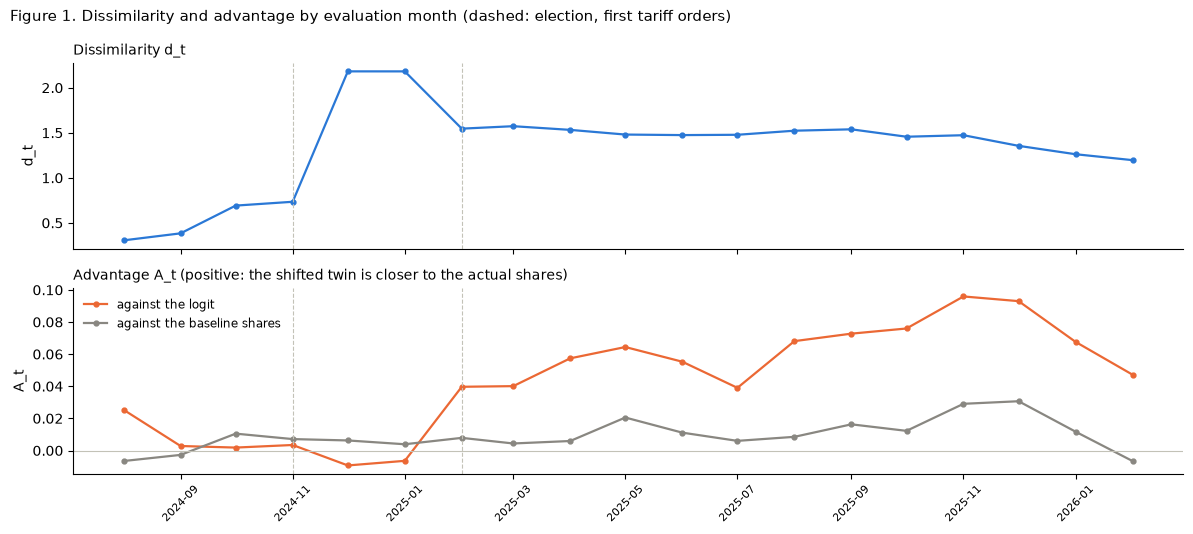

In [8]:
x = month(months.index)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 5.4), sharex=True)
top.plot(x, months.d.values, color='#2a78d6', lw=1.6, marker='o', ms=3.5)
top.set_ylabel('d_t')
for c, color in zip(COMPARATORS, ['#eb6834', '#898781']):
    bottom.plot(x, months[f'A_{c}'].values, color=color, lw=1.6, marker='o', ms=3.5, label=f'against the {NAMES[c]}')
bottom.axhline(0, color='#c3c2b7', lw=0.8); bottom.set_ylabel('A_t')
bottom.legend(frameon=False, fontsize=8.5, loc='upper left')
for ax, title in zip((top, bottom), ['Dissimilarity d_t',
                                     'Advantage A_t (positive: the shifted twin is closer to the actual shares)']):
    for d in ['2024-11-01', '2025-02-01']:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(title, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
bottom.tick_params(axis='x', labelsize=8, rotation=45)
fig.suptitle('Figure 1. Dissimilarity and advantage by evaluation month (dashed: election, first tariff orders)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

The two orderings disagree. Against the logit, A_t is small and positive through November 2024, negative in December
2024 and January 2025, the two months of highest d_t, and then rises through 2025 to 0.096 in November 2025 while d_t
drifts down. The months of highest dissimilarity are thus among the shifted twin's worst against the logit, and its
best months come late in a period of middling dissimilarity.

### 5.1 December and January

Figure 2 shows the net balance of three items, the share of favourable answers minus the share of unfavourable ones,
by month: actual, and as predicted by the baseline shares, the logit and the shifted twin.

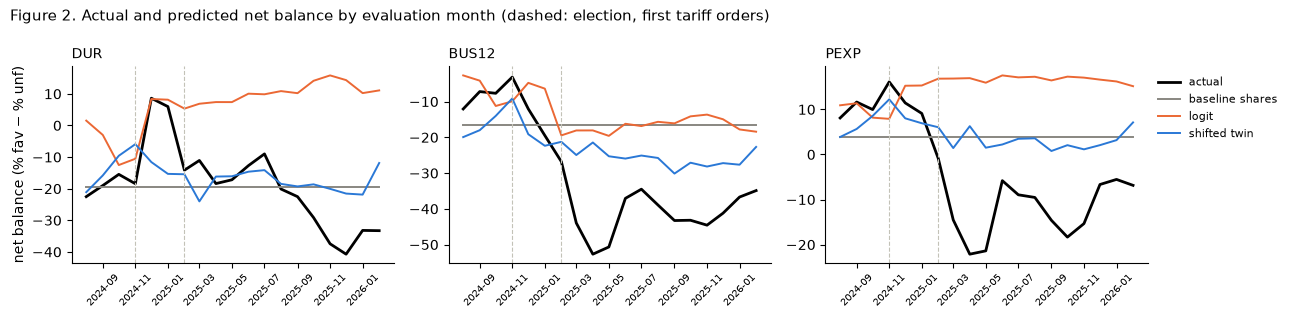

In [9]:
pred = pd.concat([pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', '==', TWIN)]),
                  pd.read_parquet(SUPERVISED / 'predictions.parquet', filters=[('model', 'in', [LOGIT, 'baseline'])])])
pred = pred[pred.CASEID.isin(test.CASEID)].join(key[['YYYYMM', 'WT', 'POLAFF'] + ITEMS], on='CASEID')
answer = pred[ITEMS].astype(object).to_numpy()[np.arange(len(pred)), pred.item.map(ITEMS.index).to_numpy()]
pred['actual_fav'], pred['actual_unf'] = answer == 'fav', answer == 'unf'
wavg = lambda g, c: np.average(g[c], weights=g.WT)

def net(g):
    """Weighted net balance, % favourable − % unfavourable: predicted by g's model, and actual."""
    return pd.Series({'predicted': 100 * (wavg(g, 'fav') - wavg(g, 'unf')),
                      'actual': 100 * (wavg(g, 'actual_fav') - wavg(g, 'actual_unf'))})

nb = pred.groupby(['item', 'model', 'YYYYMM']).apply(net, include_groups=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, item in zip(axes, ['DUR', 'BUS12', 'PEXP']):
    actual = nb.loc[(item, 'baseline'), 'actual']
    ax.plot(month(actual.index), actual.values, color='black', lw=2, label='actual')
    for m, color in [('baseline', '#898781'), (LOGIT, '#eb6834'), (TWIN, '#2a78d6')]:
        s = nb.loc[(item, m), 'predicted']
        ax.plot(month(s.index), s.values, color=color, lw=1.4, label=NAMES[m])
    for d in ['2024-11-01', '2025-02-01']:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(item, loc='left', fontsize=10); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 2. Actual and predicted net balance by evaluation month (dashed: election, first tariff orders)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

In December 2024 the net balance of `DUR` jumped from −18 to +9, its highest in the evaluation window. The logit
predicted +8 and the shifted twin −12. No input records why the answers moved: the logit attributes to the party in
power the optimism of the first Trump presidency (notebook 04, section 5.3), so its prediction rose once `winner_R`
turned to 1. That made December and January the logit's best months on `DUR` and among the shifted twin's worst.

The partisan reversal is the second part. The favourable share of `BUS12` among Republicans and Democrats, actual and
predicted, from October 2024 to March 2025, with the two party variables:

In [10]:
bus = pred[(pred.item == 'BUS12') & pred.YYYYMM.between(202410, 202503) & pred.POLAFF.isin(['Rep', 'Dem'])]
fav = bus.groupby(['YYYYMM', 'POLAFF', 'model'], observed=True).apply(lambda g: 100 * wavg(g, 'fav'),
                                                                      include_groups=False)
act = bus[bus.model == 'baseline'].groupby(['YYYYMM', 'POLAFF'], observed=True).apply(
    lambda g: 100 * wavg(g, 'actual_fav'), include_groups=False)
t = pd.concat({'actual': act.unstack(), 'logit': fav.xs(LOGIT, level='model').unstack(),
               'shifted twin': fav.xs(TWIN, level='model').unstack()}, axis=1)
pd.concat({'state': S.loc[t.index, ['pres_R', 'winner_R']]}, axis=1).join(t.round(0))

state          actual       logit       shifted twin      
       pres_R winner_R    Rep   Dem   Rep   Dem          Rep   Dem
YYYYMM                                                            
202410      0        0   11.0  36.0  11.0  32.0         16.0  25.0
202411      0        0   34.0  25.0  11.0  34.0         20.0  27.0
202412      0        1   43.0   6.0  40.0  13.0         18.0  19.0
202501      0        1   42.0   5.0  39.0  13.0         16.0  17.0
202502      1        1   49.0   3.0  27.0   7.0         24.0  12.0
202503      1        1   40.0   2.0  28.0   7.0         20.0  11.0

Respondents reversed at the election, inside the November window: Republicans rose from 11% to 34% favourable and
Democrats fell from 36% to 25%. The logit reversed in December, when `winner_R` turned to 1, as it learned from the one
precedent in training, December 2020 and January 2021. The shifted twin closed its partisan gap in December but
reversed it only in February 2025, when the president changed, and by far less: 24% against 12%, where respondents
gave 49% against 3%. The twin captures that partisans judge the economy by who holds power, but it follows the sitting
president rather than the election winner, and it understates how far partisans move.

### 5.2 The tariff months

From February 2025, answers about the economy collapsed. The net balance of `BUS12` fell from −27 in February to −53 in
April, and that of `PEXP` from −1 to −22 (Figure 2). No input carries the cause: the economic variables stayed inside
their training ranges (notebook 04, section 1), and the party variables say only that a Republican governs. Each
model's mean distance over items and months, by period:

In [11]:
d = distances.assign(period=distances.month.map(period))
d.pivot_table(index='period', columns='model', values='wasserstein').loc[
    ['Baseline', 'Flip', 'Tariffs'], [TWIN, LOGIT, 'baseline']].rename(columns=NAMES).round(3)

model,shifted twin,logit,baseline shares
period,,,
Baseline,0.023,0.033,0.024
Flip,0.044,0.040,0.050
Tariffs,0.067,0.130,0.079


All three models miss the tariff months by more than the earlier periods, so none anticipated the collapse. The logit
misses them by most, 0.130 against 0.067 for the shifted twin, because it moved the wrong way: with a Republican
president it predicted the optimism of the first Trump years, a `PEXP` net balance of +15 to +18 against an actual −22
to −1. The shifted twin moved the right way, but little: its `BUS12` net balance ranged from −21 to −30 in 2025,
against −9 to −22 before. Its advantage over the logit in 2025 therefore comes mostly from the logit's growing error,
and its smaller advantage over the baseline shares from moving the right way.

### 5.3 Advantage against time (exploratory)

The plan's first diagnostic is the Spearman correlation of d_t with elapsed months. Its exploratory sibling replaces
d_t with elapsed months in the correlation of section 3.3, with the interval and draws of section 3.4:

In [12]:
print(f"Spearman correlation of d_t with elapsed months: {primary['spearman_d_elapsed_months']:.2f}")
pd.DataFrame({NAMES[c]: primary['rho_time'][c] for c in COMPARATORS}).T.rename(
    columns={'observed': 'rho with elapsed months', 'lo': '2.5%', 'hi': '97.5%'}).round(2)

Spearman correlation of d_t with elapsed months: 0.06


,rho with elapsed months,2.5%,97.5%
logit,0.80,0.74,0.85
baseline shares,0.49,0.19,0.65


A_t rises with elapsed time against both comparators, strongly against the logit (0.80) and moderately against the
baseline shares (0.49), and both intervals lie above zero. d_t and elapsed months are nearly uncorrelated (0.06), so
each of the two correlations is close to what it would be with the other ordering held fixed. The time sibling says
when the twin gained, not why: elapsed time also orders the tariffs and every other change of 2025, and section 5.2
traced the gain to the logit's errors in those months.

### 5.4 What dissimilarity measured

d_t measured how unusual a month's input values were, and the party indicators dominated it. The months it ranked most
unusual, December 2024 and January 2025, had a precedent with the parties reversed, from which the logit had learned
the partisan reversal, whereas the change that drove the answers of 2025 appears in no input. The test therefore asked
whether the twin gains where the input values are least familiar, and in these months it does not.

Sections 5.1 and 5.2 suggest a different pattern. The twin's knowledge of how people respond to conditions is right in
direction and too weak in size, so it gains on a supervised model where that model extrapolates a wrong relationship,
as the logit did in 2025, and loses where the model's relationship holds, as the logit's did in December and January.

## 6. The plan's other analyses

### 6.1 All models

Figure 3 extends notebook 04's Figure 2 with the 12 twins: each model's skill against the baseline shares over all
evaluation months, on both scores. The twins are named by calibration, `twin` for the zero-shot twin, `twin_shift` for
the shifted twin and `twin_scale` for the scaled twin, and by feature set.

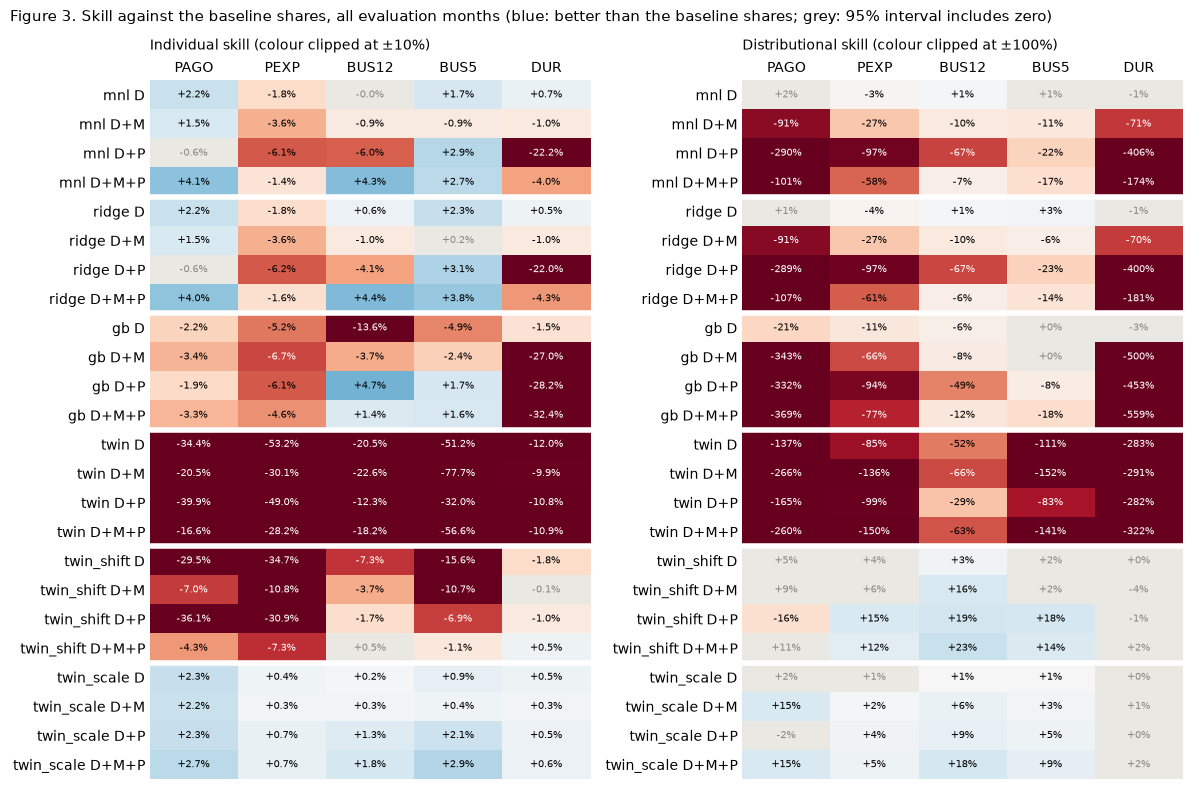

log_loss: supervised skill bounds moved by up to 0.2 points from notebook 04; cells whose interval changed sides of zero: 0
wasserstein: supervised skill bounds moved by up to 5.8 points from notebook 04; cells whose interval changed sides of zero: 0


In [13]:
def heat(ax, M, vmax, fmt, cmap, grey=None):
    """Annotated heatmap with colour clipped at ±vmax; cells where `grey` is True are drawn grey."""
    rgba = plt.get_cmap(cmap)((np.clip(M, -vmax, vmax) + vmax) / (2 * vmax))
    if grey is not None:
        rgba[grey] = to_rgba('#e9e8e3')
    ax.imshow(rgba, aspect='auto')
    for (r, c), v in np.ndenumerate(M):
        g = grey is not None and grey[r, c]
        ax.text(c, r, fmt.format(v), ha='center', va='center', fontsize=7.5,
                color='#898781' if g else 'white' if abs(np.clip(v, -vmax, vmax)) > 0.65 * vmax else 'black')
    ax.tick_params(length=0); ax.spines[:].set_visible(False); ax.xaxis.tick_top()

allc = scores[(scores.period == 'all') & (scores.group == 'all')].set_index(['model', 'item'])
rows = [(f, fs) for f in ['mnl', 'ridge', 'gb', 'twin', 'twin_shift', 'twin_scale'] for fs in SHORT]
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, (s, title, vmax, fmt) in zip(axes, [('log_loss_skill', 'Individual skill', 0.1, '{:+.1%}'),
                                            ('wasserstein_skill', 'Distributional skill', 1.0, '{:+.0%}')]):
    cell = lambda col: np.array([[allc.loc[(f'{f}_{fs}', i), col] for i in ITEMS] for f, fs in rows])
    heat(ax, cell(s), vmax, fmt, 'RdBu', grey=(cell(f'{s}_lo') <= 0) & (cell(f'{s}_hi') >= 0))
    ax.set_xticks(range(len(ITEMS)), ITEMS); ax.set_yticks(range(len(rows)), [f'{f} {SHORT[fs]}' for f, fs in rows])
    for y in np.arange(3.5, len(rows) - 1, 4):
        ax.axhline(y, color='white', lw=4)
    ax.set_title(f'{title} (colour clipped at ±{vmax:.0%})', loc='left', fontsize=10, pad=22)
fig.suptitle('Figure 3. Skill against the baseline shares, all evaluation months (blue: better than the baseline shares; '
             'grey: 95% interval includes zero)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

old = pd.read_csv(SUPERVISED / 'scores.csv').query("period == 'all' and group == 'all'").set_index(['model', 'item'])
old = old[old.log_loss_skill.notna()]
new = allc.loc[old.index]
for s in ['log_loss', 'wasserstein']:
    b = [f'{s}_skill_lo', f'{s}_skill_hi']
    flips = (((old[b[0]] > 0) | (old[b[1]] < 0)) != ((new[b[0]] > 0) | (new[b[1]] < 0))).sum()
    print(f'{s}: supervised skill bounds moved by up to {100 * (new[b] - old[b]).abs().max().max():.1f} points '
          f'from notebook 04; cells whose interval changed sides of zero: {flips}')

On the distributional score, the shifted and scaled twins with state variables beat the baseline shares on most items,
whereas all but one of the 45 combinations of a supervised model with state variables and an item lose to them. The shifted twin on
D+M+P gains 2% to 23% on every item, with intervals above zero on `PEXP`, `BUS12` and `BUS5`.

On the individual score, the shifted twin loses to the baseline shares on three items, because its differences between
respondents are too large (notebook 05, section 3.2). The scaled twin, whose fitted scale shrinks them, gains 0.2% to
2.9% on every item and feature set. The zero-shot twin loses on every item on both scores.

The supervised intervals come from the shared draws of section 3.4, and the changes from notebook 04, printed above,
move no interval across zero.

### 6.2 What the state adds

Notebook 04 found that state variables make every supervised family's answer shares worse. The same comparison for the
logit and the twins, as D+M+P minus D over all evaluation months, in Wasserstein distance and log loss (negative:
D+M+P is better; *: the 95% interval excludes zero):

In [14]:
pairs = scores[(scores.period == 'all') & (scores.group == 'all')].set_index(['model', 'item'])
mark = lambda r, s: f"{r[s]:+.3f}{'*' if r[f'{s}_lo'] > 0 or r[f'{s}_hi'] < 0 else ''}"
pd.DataFrame({(s, name): {i: mark(pairs.loc[(f'{f}_{DMP}-{f}_demographics', i)], s) for i in ITEMS}
              for s in ['wasserstein', 'log_loss']
              for f, name in [('mnl', 'logit'), ('twin_shift', 'shifted twin'), ('twin_scale', 'scaled twin')]})

wasserstein                          log_loss                         
            logit shifted twin scaled twin    logit shifted twin scaled twin
PAGO      +0.032*       -0.002     -0.004*  -0.020*      -0.268*     -0.004*
PEXP      +0.037*      -0.005*     -0.003*  -0.005*      -0.304*     -0.004*
BUS12     +0.007*      -0.018*     -0.016*  -0.046*      -0.082*     -0.016*
BUS5      +0.016*      -0.011*     -0.007*  -0.010*      -0.156*     -0.022*
DUR       +0.081*       -0.001      -0.001  +0.033*      -0.017*      -0.000

The state variables improve both twins on both scores, whereas they worsen the logit's answer shares on every item. On
answer shares, they lower the shifted twin's distance on every item, by enough to exclude zero on three. On individual
answers, they lower both twins' log loss on every item except the scaled twin's on `DUR`, which is unchanged, whereas
the logit loses on `DUR`. The twins' reading of the state carries over to the evaluation window, whereas the logit's
coefficients for it, fitted on 90 months dominated by a few episodes, do not.

### 6.3 Parties

The shifted twin minus the logit for each party over all evaluation months, in both scores (negative: the shifted twin
is better; *: the 95% interval excludes zero):

In [15]:
party = scores[(scores.period == 'all') & (scores.model == f'{TWIN}-{LOGIT}')].set_index(['group', 'item'])
pd.DataFrame({(s, g): {i: mark(party.loc[(g, i)], s) for i in ITEMS} for s in ['wasserstein', 'log_loss']
              for g in ['all', 'Rep', 'Dem', 'Ind']})

wasserstein                            log_loss                    \
              all      Rep      Dem      Ind      all      Rep      Dem   
PAGO      -0.035*  +0.056*   +0.006  -0.060*  +0.090*  +0.109*  +0.086*   
PEXP      -0.047*  +0.052*  -0.003*  -0.045*  +0.067*  +0.110*  +0.054*   
BUS12     -0.028*  +0.104*  +0.038*  -0.041*  +0.041*  +0.135*  +0.081*   
BUS5      -0.028*  +0.033*  -0.013*  -0.019*  +0.040*  +0.102*   +0.003   
DUR       -0.082*  -0.051*  -0.038*  -0.071*  -0.032*  -0.033*  -0.027*   

                
           Ind  
PAGO   +0.052*  
PEXP   +0.049*  
BUS12  -0.027*  
BUS5   +0.042*  
DUR    -0.038*

The shifted twin beats the logit on answer shares for all respondents and for independents on every item, but loses to
it for Republicans on four items. The logit's party products track how each party's answers moved (section 5.1), so
its error lies in the level shared by everyone, which shows most among independents, who have no product. On
individual answers the logit is better in most cells, because the shifted twin's differences between respondents are
too large (section 6.1).

### 6.4 Calibration across periods

The plan's second diagnostic refits the two calibrations of notebook 05, section 3.1, on each evaluation period's
interviews, from the zero-shot twin's probabilities on D+M+P. The refits change no prediction; they show how far the
training fit lies from the best fit in each period. To judge a gap against sampling noise, the training fit is
repeated on 200 redraws of its interviews within months (exploratory). The period fits use more interviews than the
training fit, about 3,000 in Baseline and Flip and 15,000 in Tariffs against 2,200, so they are no noisier.

In [16]:
z = pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', '==', f'twin_{DMP}')])
z = z[z.CASEID.isin(train[train.web == 1].CASEID)].join(key[['YYYYMM', 'WT'] + ITEMS], on='CASEID')
rng, redrawn = np.random.default_rng(0), []
for item, g in z.groupby('item'):
    g = g.reset_index(drop=True)
    within = [np.flatnonzero(g.YYYYMM.to_numpy() == m) for m in g.YYYYMM.unique()]
    for _ in range(200):
        r = g.iloc[np.concatenate([rng.choice(ix, len(ix)) for ix in within])]
        for name, scale in [('shift', False), ('scale', True)]:
            c = twin.fit_calibration(r[CLASSES], r[item].astype(str), r.WT, scale)
            redrawn.append({'item': item, 'calibration': name, 'a': c['a'], 'b_fav': c['fav'], 'b_unf': c['unf']})
redrawn = pd.DataFrame(redrawn)
p = by_period[by_period.feature_set == DMP]
out = {}
for param, name, label in [('a', 'scale', 'a (scaled twin)'), ('b_fav', 'shift', 'b_fav (shifted twin)'),
                           ('b_unf', 'shift', 'b_unf (shifted twin)')]:
    fit = p[p.calibration == name].pivot(index='item', columns='fitted_on', values=param)
    for item in ITEMS:
        lo, hi = np.percentile(redrawn[(redrawn.calibration == name) & (redrawn.item == item)][param], [2.5, 97.5])
        out[(label, item)] = {'training web': f"{fit.loc[item, 'training web']:.2f}",
                              'its 95% range': f'[{lo:.2f}, {hi:.2f}]',
                              **{q: f'{fit.loc[item, q]:.2f}' for q in ['Baseline', 'Flip', 'Tariffs']}}
pd.DataFrame(out).T

training web  its 95% range Baseline  Flip Tariffs
a (scaled twin)      PAGO          0.46   [0.37, 0.53]     0.39  0.38    0.35
                     PEXP          0.30   [0.21, 0.41]     0.34  0.11    0.21
                     BUS12         0.61   [0.47, 0.76]     0.67  0.07    0.34
                     BUS5          0.31   [0.22, 0.42]     0.35  0.00    0.47
                     DUR           0.95   [0.62, 1.32]     1.04  0.70    0.52
b_fav (shifted twin) PAGO          0.69   [0.54, 0.82]     0.69  0.53    0.49
                     PEXP          1.23   [1.09, 1.36]     1.30  1.51    1.36
                     BUS12         0.59   [0.48, 0.73]     0.74  0.80    1.14
                     BUS5          1.20   [1.06, 1.33]     1.46  1.63    1.91
                     DUR          -0.39  [-0.81, 0.17]    -0.08  0.20    0.03
b_unf (shifted twin) PAGO          1.55   [1.41, 1.70]     1.53  1.19    1.28
                     PEXP          1.00   [0.89, 1.16]     0.88  1.18    1.76
                     BUS12         0.93   [0.82, 1.07]     0.70  0.89    1.78
                     BUS5          2.06   [1.91, 2.20]     1.90  2.28    2.98
                     DUR           0.38  [-0.05, 0.94]     0.76  0.75    0.90

The two largest changes lie well outside the training range. In Flip, the fitted scale a falls to between 0.00 and 0.11 on
`BUS12`, `BUS5` and `PEXP`, so the best fit nearly ignores the twin's differences between respondents, as the wrong
partisan ordering of section 5.1 implies. In Tariffs, b_unf rises by 0.8 to 0.9 on the same three items, and b_fav by
less, so respondents left the middle answer, mostly for the unfavourable one, more than the twin predicted, which is
the collapse of section 5.2. Neither change shows whether the survey's form changed, because a refitted constant
absorbs the twin's error about opinions along with any change in how the form records them.

## 7. Deviations and limits

The analysis follows the plan with no deviation. Three things the plan left open were fixed in code and committed
before the scoring run (`33be4cd`): the bootstrap's shared draws of whole interviews (`e633def`), the exploratory
leave-one-month-out values and time sibling (`f2c54fc`, `0f6b6bc`), and the scoring command's input checks
(`3ce725b`). This notebook adds one exploratory analysis after scoring, the redraws of the training fit in section 6.4.

Three limits bound the result. The intervals count only respondent sampling, with the 19 months held fixed. The
evidence across months is closer to three episodes than to 19 independent months, because d_t and A_t move in blocks
of consecutive months. And the study tests one model, one prompt and one survey.

## 8. What this study establishes

- **The preregistered test is inconclusive.** Against both comparators, the rank correlation between dissimilarity and
  the shifted twin's advantage is close to zero, with intervals that include it.
- **The twin's advantage rose with time instead (exploratory).** It came mostly from the logit, whose state
  coefficients projected the optimism of the first Trump presidency onto 2025 while sentiment collapsed for reasons no
  input records.
- **On answer shares over the whole window, the shifted twin beats the logit on the same inputs on every item.** State
  variables improve the twins' answer shares and worsen the supervised models'.
- **The twin's knowledge of partisan response is right in direction and too weak in size.** It follows the sitting
  president rather than the election winner, so it reversed three months after respondents did.

Rolling training and evaluation windows, each fitted on the months before it and predicting the next, would give many
episodes instead of three. A prompt that names the election winner as the incoming president would show whether the
twin's lag at the transition comes from the prompt or from the model.